# v3 - 2. Is the data trustworthy?
Development data only (train + validation). The test buckets are not read, except for their ids.

In [1]:
import os, sys
from pathlib import Path
os.environ["TOADWATCH_VERSION"] = "v3"          # selects the strict "true accuracy" study (v3); keep this line first
sys.path.insert(0, str(Path.cwd().parent))       # notebooks live in ToadWatch_PR/notebooks
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.width", 190); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 120)
from toadwatch import config as C, workflow_v3 as W, protocol_v3 as P, charts_v3 as CH, reporting as R
print("version:", C.VERSION, "| seed:", C.SEED, "| outputs:", C.OUTPUTS_DIR)

version: v3 | seed: 2028 | outputs: /home/rush/Downloads/Fase/ToadWatch_PR/outputs/v3


In [2]:
a = W.audit()
display(a['ceilings'].to_frame())

,accuracy
majority_class,0.601050
call_oracle,0.848936
message_oracle,0.848936
both_channels_oracle,1.000000


### Ceilings
`call_oracle` / `message_oracle` = the best accuracy of a model that knows ONE channel's true label perfectly. **A single-channel model above its ceiling would prove leakage.** Using both channels, 100 % is possible.

In [3]:
display(a['overlap'])

,check,shared,ok
0,call ids shared test/dev,0,True
1,message ids shared test/dev,0,True
2,call families shared test/dev,0,True
3,message families shared test/dev,0,True
4,call families shared fold 0/1,0,True
5,message families shared fold 0/1,0,True
6,call families shared fold 0/2,0,True
7,message families shared fold 0/2,0,True
8,call families shared fold 1/3,0,True
9,message families shared fold 1/3,0,True


### Shortcut baselines (labels predicted from metadata only)
In the **hard** regime every baseline must equal the majority-class rate. In the **public** regime the sources give the answer away - this is why public-data scores near 100 % are not believable.

,baseline,accuracy,balanced_accuracy,f1,accuracy_on_hard_regime,accuracy_on_public_regime
0,message type only,0.601,0.500,0.000,0.602,0.601
1,message language only,0.601,0.500,0.000,0.602,0.601
2,hard-vs-public flag only,0.601,0.500,0.000,0.602,0.601
3,call source only,0.816,0.825,0.790,0.602,0.849
4,message source only,0.816,0.824,0.789,0.602,0.849
5,call source + message source,0.944,0.929,0.924,0.602,0.996


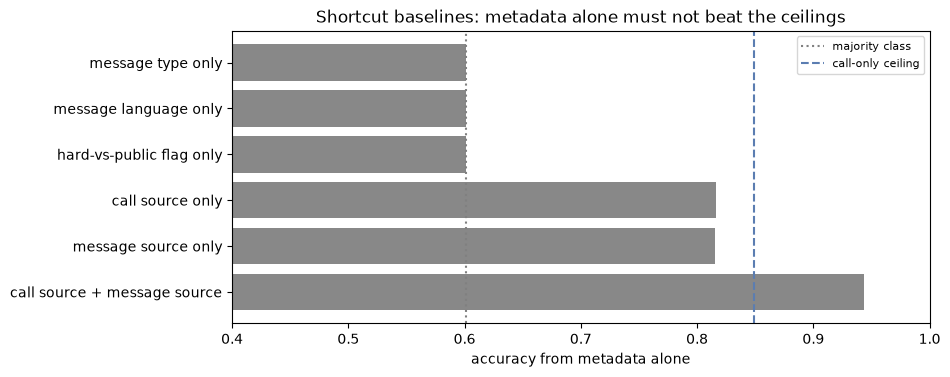

In [4]:
display(a['shortcuts'].round(3)); CH.plot_shortcuts(a['shortcuts'], a['ceilings'].to_dict(), 'v3_05_shortcut_baselines'); plt.show()

### Near-copies between folds
Share of texts with a near-copy (cosine > 0.8) in the OTHER development folds. Family bucketing should keep this small.

In [5]:
display(a['near_dup'].round(3))

,channel,fold,share_with_near_copy_(cos>0.8)
0,call,0,0.000
1,call,1,0.000
2,call,2,0.000
3,call,3,0.000
4,message,0,0.110
5,message,1,0.103
6,message,2,0.105
7,message,3,0.098


### Label audit - please read these
Items whose label a held-out model contradicts most confidently. Not automatic verdicts: it is a short list for a human. If you find wrong labels, tell me the source and I will drop or fix them.

,channel,source,items,suspects,mean_prob_of_given_label,suspect_share
40,message,spaphish_legitimate_0,39,2,0.545,0.051
30,message,spam_json,97,4,0.623,0.041
15,message,hard_sms,325,9,0.711,0.028
25,message,legitimate_json,37,1,0.594,0.027
41,message,spaphish_phishing_1,78,2,0.700,0.026
16,message,legitimate_emails_CEAS_08,88,1,0.820,0.011
22,message,legitimate_emails_TREC_05,107,1,0.807,0.009
39,message,spam_scam_emails_TREC_07,147,1,0.777,0.007
0,call,agent_conversation_labels_0,135,0,0.951,0.000
1,call,agent_conversation_labels_1,642,0,0.982,0.000


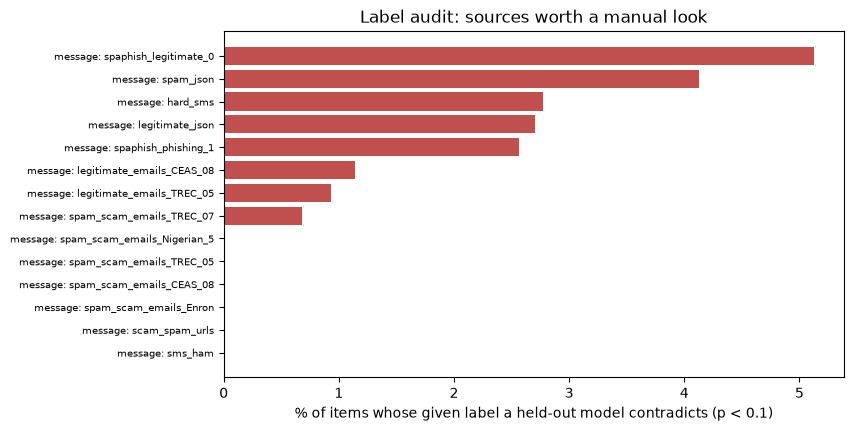

,channel,id,source,given_label,prob_of_given_label,text_start
0,message,spam_json_3384,spam_json,1,0.019987,https://www2.mstacunsrc.icu/
1,message,legitimate_emails_3306,legitimate_emails_CEAS_08,0,0.052236,3 Day Weekend Sale - Low Prices This Weekend Only! J&R Weekend Sale http://jr.chtah.com/a/tBHrFg$AJMkGtBwruZMAFqBnPX...
2,message,legitimate_emails_3598,legitimate_emails_TREC_05,0,0.055330,man night again? Zero response from my last effort on this matter. Are your emails working men? Zander called and su...
3,message,spam_json_4307,spam_json,1,0.055681,https://www.visaeis-vsiaoeod.lcvlnpl.presse.ci
4,message,legitimate_json_2065,legitimate_json,0,0.059679,http://gnoted.com/how-to-search-for-words-inside-documents-text-files-windows-7/
5,message,spaphish_phishing_1_438,spaphish_phishing_1,1,0.070802,"Fw: GRACIAS POR VUESTRA PACIENCIA DURANTE TODO ESTE TIEMPO Buenas noticias para ti, mi amigo Querido amigo, ¿cómo es..."
6,message,hardmsg_231,hard_sms,1,0.074250,"Hi mom, it's me. I'm in a bit of a bind and I don't want to worry anyone. Can you send $86.25 to this account for me..."
7,message,spaphish_legitimate_0_361,spaphish_legitimate_0,0,0.075936,Patient Link - BUSTIO FUENTES^Genovevo ANTONIO^ Tu estudio está listo!!! R004 SANTIAGO RAMÍREZ agradece tu preferenc...
8,message,hardmsg_513,hard_sms,0,0.076181,ATH Móvil: su envío de $127.50 a Ana fue completado. Gracias por usar ATH Móvil.
9,message,hardmsg_211,hard_sms,1,0.080623,"Hi mom, it's me. I'm in a bit of a bind and I don't want to worry anyone. Can you send $49.99 to this account for me..."


In [6]:
display(a['suspect_summary'].head(12).round(3)); CH.plot_label_audit(a['suspect_summary'], 'v3_06_label_audit'); plt.show()
a['suspects'].head(25)